# Predicting the Harvard-Yale Game with Least Squares

**Goal:** fit a scoring model for Yale and one for Harvard on 2016-2025 Ivy League game data, check how well each model predicts the 2026 games it never saw, then use each team's current-season form to predict the score of the upcoming Harvard-Yale game.

Each model predicts points scored as:

```
points = z0 + z1*YPP + z2*3D% + z3*TO + z4*YPP_opp + z5*3D%_opp + z6*TK_opp + z7*Home
```

| Metric | Meaning |
| --- | --- |
| `YPP` | target team offensive yards per play |
| `3D%` | target team offensive third-down conversion percentage |
| `TO` | target team offensive turnovers per game |
| `YPP_opp` | opponent yards per play allowed |
| `3D%_opp` | opponent third-down conversion percentage allowed |
| `TK_opp` | opponent takeaways per game |
| `Home` | 1 if home, 0 if away or neutral |

The first three describe the team's own offense and the `_opp` terms describe the opponent's defense, so each row is a matchup, not a single team. Every stat is a season-to-date average computed only from games played *before* the game being modeled, so no game predicts itself.

With more games than unknowns, `A z = b` is overdetermined (A is the m×8 data matrix, one row per game, and b is the vector of points scored). By the Best Approximation Theorem (Theorem 5.6.1), the `z` that minimizes `‖b − A z‖` solves the normal equations:

```
(A^T A) z = A^T b
```

The predicted points are `p = A z`.

## Input data

Two CSVs with the same columns, loaded as two DataFrames:

- **`fit_df`**: `data/ivy_team_games_2016_2025.csv`, used to fit the coefficients (2020 had no season)
- **`eval_df`**: `data/ivy_team_games_2026.csv`, used to evaluate the fitted models and to supply 2026 form for the prediction

One row per team-game (each game appears twice, once per team):

| Column | Meaning |
| --- | --- |
| `team`, `opponent` | team names as used in the filters, e.g. `yale`, `harvard` |
| `season`, `date` | season year, and the game date as a sortable `YYYY-MM-DD` string |
| `home` | 1 if `team` played at home, 0 otherwise (0 for both teams at a neutral site) |
| `team_pts` | points scored by `team`, the quantity being modeled |
| `team_total_yds`, `team_total_plays` | offensive yards and play count for `team` |
| `team_third_down_conv`, `team_third_down_att` | third downs converted and attempted by `team` |
| `team_turnovers` | turnovers committed by `team` |
| `opp_total_yds`, `opp_total_plays` | yards and plays allowed by the defense of `team` |
| `opp_third_down_conv`, `opp_third_down_att` | third downs allowed and faced by the defense of `team` |
| `opp_turnovers` | turnovers forced by the defense of `team` |

## Imports

`pandas` loads and filters the game log, `numpy` solves the normal equations, and `matplotlib` plots predicted vs. actual scores.

In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

## Building the least-squares system

Every data function takes a DataFrame `df` as its first argument, so the same code builds rows from either `fit_df` or `eval_df`.

- **`average(df, date, season, team)`**: season-to-date offense (`YPP`, `3D`, `TO`) and defense (`YPP_opp`, `3D_opp`, `TK_opp`) for `team`, using only games in `df` before `date`. Returns `None` for season openers (no prior games).
- **`buildrow(df, date, team)`**: one game as a row of `A`, `[1, YPP, 3D, TO, YPP_opp, 3D_opp, TK_opp, Home]`, paired with `team_pts` as the matching entry of `b`. The team supplies `YPP`, `3D`, `TO`; the opponent supplies its defensive `YPP_opp`, `3D_opp`, `TK_opp`. Returns `None` if either team has no prior games that season.
- **`buildmatrix(df, team)`**: stacks every valid row/points pair for `team` in `df` into `A` and `b`. Season openers are skipped automatically.
- **`calc(team)`**: solves `(A^T A) z = A^T b` for `z`, rounded to 2 decimals. It **always** fits on `fit_df`, so 2026 games never influence the coefficients.

In [8]:
# Notation (Best Approximation Theorem, Theorem 5.6.1):
#   A   m x 8 data matrix, one row per game
#   b   actual points scored
#   z   coefficients [z0, ..., z7], the solution of (A^T A) z = A^T b
#   p   predicted points, A z
#
#   z0 intercept   z1 YPP       z2 3D%       z3 TO
#   z4 YPP_opp     z5 3D%_opp   z6 TK_opp    z7 Home

fit_df = pd.read_csv("../data/ivy_team_games_2016_2025.csv")
eval_df = pd.read_csv("../data/ivy_team_games_2026.csv")

def average(df, date, season, team):
    games = df[(df["team"] == team) & (df["season"] == season) & (df["date"] < date)]

    if len(games) == 0:
        return None

    stats = {}

    stats["YPP"] = games["team_total_yds"].sum() / games["team_total_plays"].sum()
    stats["3D"]  = games["team_third_down_conv"].sum() / games["team_third_down_att"].sum()
    stats["TO"]  = games["team_turnovers"].sum() / len(games)

    stats["YPP_opp"] = games["opp_total_yds"].sum() / games["opp_total_plays"].sum()
    stats["3D_opp"]  = games["opp_third_down_conv"].sum() / games["opp_third_down_att"].sum()
    stats["TK_opp"]  = games["opp_turnovers"].sum() / len(games)

    return stats

def buildrow(df, date, team):
    matches = df[(df["date"] == date) & (df["team"] == team)]

    if len(matches) != 1:
        return None

    game = matches.iloc[0]
    team_stats = average(df, date, game["season"], team)
    opp_stats = average(df, date, game["season"], game["opponent"])

    if team_stats is None or opp_stats is None:
        return None

    row = [1, team_stats["YPP"], team_stats["3D"], team_stats["TO"], opp_stats["YPP_opp"], opp_stats["3D_opp"], opp_stats["TK_opp"], game["home"]]

    return [row, game["team_pts"]]

def buildmatrix(df, team):
    A = []
    b = []

    for game in df[df["team"] == team].itertuples():
        result = buildrow(df, game.date, team)

        if result is None:
            continue

        A.append(result[0])
        b.append(result[1])

    return [A, b]

def calc(team):
    A, b = buildmatrix(fit_df, team)
    A = np.array(A)
    A_T = np.transpose(A)
    b = np.array(b)

    z = np.linalg.solve(np.matmul(A_T, A), np.matmul(A_T, b))

    return np.round(z, 2)

## Fitting the two models

`calc` returns `z` in the same order as the columns of `A`:

```
[z0, z1, z2, z3, z4, z5, z6, z7] = [intercept, YPP, 3D%, TO, YPP_opp, 3D%_opp, TK_opp, Home]
```

The predictors are on very different scales (yards/play ≈ 5, rates ∈ [0,1], turnovers/game ≈ 1-2), so coefficient size isn't directly comparable across terms.

In [9]:
print("Yale z:   ", calc("yale"))
print("Harvard z:", calc("harvard"))

Yale z:    [-14.1    0.94  23.42  -4.09   6.29   5.93  -2.46   8.03]
Harvard z: [37.45 -5.66 31.64 -8.39  2.21 29.13 -1.95 -1.32]


## Evaluation

`plot(df, team, color, years)` builds `A` and `b` from `df` with `buildmatrix`, predicts `p = A z` with the fitted coefficients (`np.matmul(A, calc(team))`), plots `p` vs. `b`, and returns the RMSE: the typical size of a prediction miss in points. Points on the dashed line were predicted exactly.

It runs twice per team:

- on **`fit_df`** (2016-2025): how well the model matches the games it was fit on
- on **`eval_df`** (2026): how well it predicts games it never saw

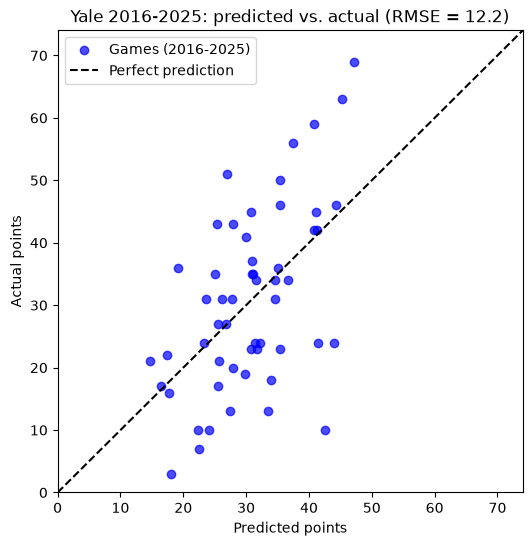

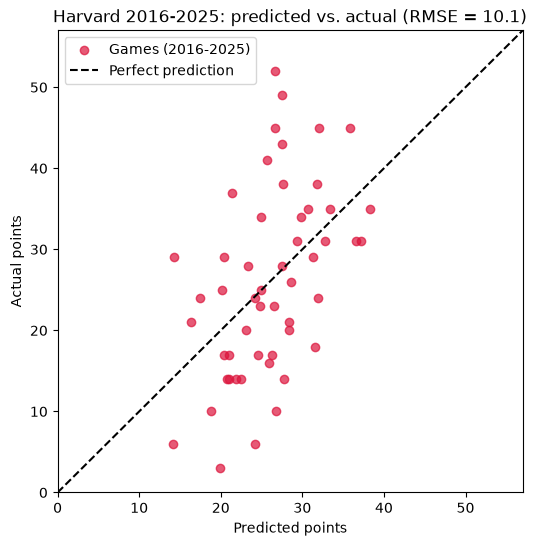

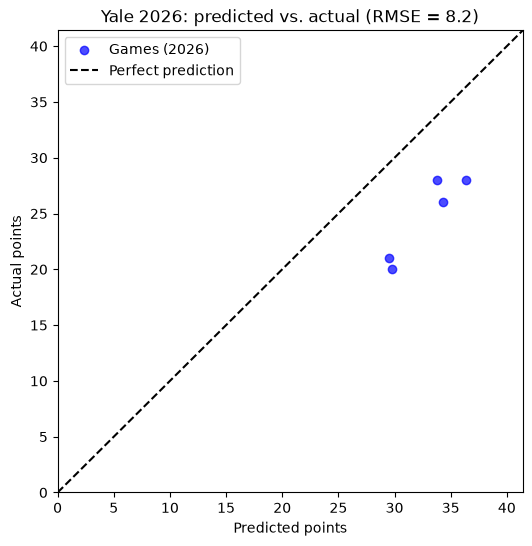

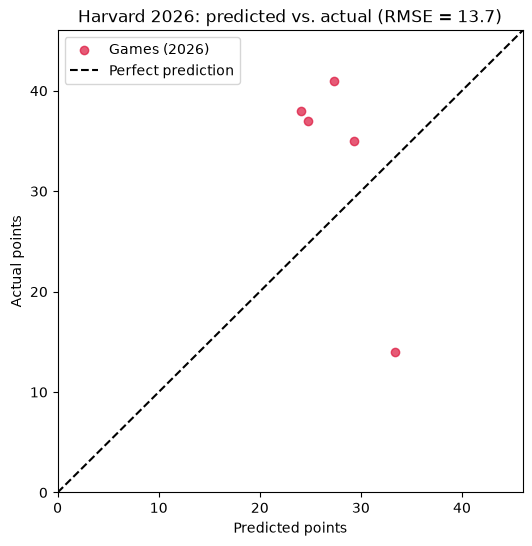

Yale RMSE: 12.2 (2016-2025), 8.2 (2026)
Harvard RMSE: 10.1 (2016-2025), 13.7 (2026)


In [10]:
def plot(df, team, color, years):
    A, b = buildmatrix(df, team)
    A = np.array(A)
    b = np.array(b)

    z = calc(team)
    p = np.matmul(A, z)
    err = np.sqrt(np.mean((b - p) ** 2))

    plt.figure(figsize=(6, 6))
    plt.scatter(p, b, alpha=0.7, label=f"Games ({years})", color=color)

    low, high = 0, max(b.max(), p.max()) + 5
    plt.plot([low, high], [low, high], "k--", label="Perfect prediction")

    plt.xlim(low, high)
    plt.ylim(low, high)
    plt.xlabel("Predicted points")
    plt.ylabel("Actual points")
    plt.title(f"{team.capitalize()} {years}: predicted vs. actual (RMSE = {err:.1f})")
    plt.legend()
    plt.show()

    return err

teams = ["yale", "harvard"]
team_color = {"yale": "blue", "harvard": "crimson"}

rmse = {team: plot(fit_df, team, team_color[team], "2016-2025") for team in teams}
rmse_test = {team: plot(eval_df, team, team_color[team], "2026") for team in teams}

for team in teams:
    print(f"{team.capitalize()} RMSE: {rmse[team]:.1f} (2016-2025), {rmse_test[team]:.1f} (2026)")

## Predicting the Harvard-Yale game

`predict` builds the same row of `A` as `buildrow`, `[1, YPP, 3D, TO, YPP_opp, 3D_opp, TK_opp, Home]`, using each team's 2026 averages from games before the game date, and multiplies it by that team's `z` to get `p`. The game hasn't been played, so there is no actual score; the 2016-2025 `rmse` from above is shown as a rough error bar.

In [11]:
def predict(date, season, team, opp, home):
    team_stats = average(eval_df, date, season, team)
    opp_stats = average(eval_df, date, season, opp)
    row = [1, team_stats["YPP"], team_stats["3D"], team_stats["TO"], opp_stats["YPP_opp"], opp_stats["3D_opp"], opp_stats["TK_opp"], home]

    z = calc(team)
    p = np.dot(z, row)

    return p

# Home = 0 for both teams means a neutral site
yale_score = predict("2026-11-21", 2026, "yale", "harvard", 0)
harvard_score = predict("2026-11-21", 2026, "harvard", "yale", 0)

print(f"Yale:    {yale_score:.1f} ± {rmse['yale']:.1f}")
print(f"Harvard: {harvard_score:.1f} ± {rmse['harvard']:.1f}")

Yale:    19.8 ± 12.2
Harvard: 19.2 ± 10.1
